# Gasto en pensiones y carencia material de las personas mayores

In [ ]:
# Parámetros de la gráfica
SLUG = "seguridad-social"  # carpeta en research/temas/
GRAFICA_ID = "gasto-pensiones-carencia-mayores"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Gasto en pensiones y carencia material de las personas mayores"  # `titulo` de la gráfica en config.json
DESDE = 1976  # primer año candidato (METODOLOGIA §2.3)
UNIVERSO = "ue27"  # ocde | ue27: todos sus países con dato en los dos ejes (METODOLOGIA §2.6)
EJE_X = {"titulo": "Gasto en pensiones", "unidad": "% del PIB"}
EJE_Y = {"titulo": "Personas de 65 años o más en carencia material y social severa", "unidad": "% de la población de 65 años o más"}
EDAD_Y = "Y_GE65"  # tramo de edad del eje y en EU-SILC
ANIOS = None  # (desde, hasta) si el config fija una ventana; None = último año común de cada país
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

Cada punto es un país de la UE-27 con dato en los dos ejes el mismo año.

- **Eje horizontal:** el **gasto en pensiones** de jubilación (incluidas las anticipadas y parciales) y de supervivencia, en porcentaje del PIB (Eurostat, ESSPROS). Además del gasto público, ESSPROS cuenta los regímenes privados que considera protección social, como algunos planes de empresa obligatorios.
- **Eje vertical:** el porcentaje de las personas de 65 años o más en **carencia material y social severa**: personas que no pueden permitirse al menos 7 de 13 gastos básicos (pagar a tiempo el alquiler, la hipoteca o los recibos, mantener la vivienda a una temperatura adecuada, afrontar un gasto imprevisto, comer carne o pescado cada dos días, una semana de vacaciones al año, sustituir ropa o muebles estropeados, un coche, conexión a internet, etc.). Es el indicador de la UE que forma parte de la tasa de riesgo de pobreza o exclusión social (AROPE).

**Por qué este indicador y no la pobreza relativa.** La tasa de riesgo de pobreza cuenta a quienes tienen una renta inferior al 60 % (o al 50 %) de la mediana de su país: mide la renta frente a la del resto de la población, y no si alguien puede pagar lo básico. La carencia material no depende de la mediana: pregunta directamente por lo que el hogar puede permitirse, con la misma lista en todos los países de la UE.

**Para qué sirve.** Es el argumento de quienes defienden subir o mantener las pensiones. Su pareja es `gasto-pensiones-carencia-infantil`, con el argumento de quienes sostienen que el gasto en pensiones deja menos recursos para las generaciones jóvenes. **La relación entre dos indicadores no muestra que uno cause el otro**: no se dibuja línea de tendencia ni se calcula la correlación.

**Limitaciones.**
- El gasto en porcentaje del PIB depende también de cuántas personas mayores hay en cada país, no solo de cuánto cobra cada una.
- La carencia de las personas mayores depende también de otras rentas (planes de empresa, ahorro) y de si tienen la vivienda pagada, no solo de la pensión pública.
- La lista de gastos es la misma en todos los países, pero lo que significa no poder permitirse cada uno cambia con el clima, los precios y las costumbres de cada país.
- Solo hay datos de la UE (encuesta EU-SILC), por eso el universo es la UE-27 y no la OCDE. Eurostat publica el indicador desde 2015.

## 2. Descarga

- **Eje x:** Eurostat, gasto en pensiones de la protección social (`spr_exp_pens`, ESSPROS), suma de las pensiones de jubilación (`OLD`), jubilación anticipada (`AOLD`), jubilación parcial (`PART`) y supervivencia (`SRV`), todas las pensiones con y sin comprobación de recursos (`spdepm=TOTAL`), en % del PIB (`PC_GDP`). Quedan fuera las pensiones de incapacidad y las prejubilaciones, como en la base de gasto social de la OCDE que usa `gasto-pensiones-pib`.
- **Eje y:** Eurostat, EU-SILC, tasa de carencia material y social severa (`ilc_mdsd11`), población de 65 años o más (`Y_GE65`), ambos sexos, en %.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.paises import CODIGOS_EUROSTAT, paises_de
from lib.writer import construir_dispersion_data, write_dispersion_data

from datetime import date

from lib import eurostat
from lib.tipos import FuenteMeta

PAISES = paises_de(UNIVERSO)
GEOS = {CODIGOS_EUROSTAT[c]: c for c in PAISES} | {"EU27_2020": "EU27_2020"}  # código Eurostat → código del punto
HOY = date.today().isoformat()

PENSIONES = ("OLD", "AOLD", "PART", "SRV")  # jubilación, anticipada, parcial y supervivencia
partes = []
for tipo in PENSIONES:
    d, _ = eurostat.get("spr_exp_pens", {"freq": "A", "spdepb": tipo, "spdepm": "TOTAL", "unit": "PC_GDP"}, geos=GEOS, desde=DESDE)
    partes.append(d.set_index(["serie", "periodo"])["valor"].rename(tipo))
y, _ = eurostat.get("ilc_mdsd11", {"freq": "A", "unit": "PC", "sex": "T", "age": EDAD_Y}, geos=GEOS, desde=DESDE)
print("Con carencia material:", y["serie"].nunique(), "· años:", y["periodo"].min(), "-", y["periodo"].max())

Con carencia material: 28 · años: 2015 - 2025


## 3. Transformación

1. **Eje x:** suma de los cuatro tipos de pensión de cada país y año; si falta alguno de los cuatro (Eurostat lo deja vacío cuando el país no tiene ese tipo de pensión o no lo publica), se toma como 0 solo si el país publica el total de pensiones ese año. Se comprueba que la suma no supera el total de pensiones (`TOTAL`).
2. **Eje y:** tal como lo publica Eurostat.
3. **Media de la UE-27:** Eurostat publica las dos para el agregado `EU27_2020`; el escritor la añade como punto si tiene dato en los dos ejes el mismo año.
4. El escritor elige para cada país el último año con dato en los dos ejes, el mismo para `x` e `y`.

In [ ]:
total, _ = eurostat.get("spr_exp_pens", {"freq": "A", "spdepb": "TOTAL", "spdepm": "TOTAL", "unit": "PC_GDP"}, geos=GEOS, desde=DESDE)
total = total.set_index(["serie", "periodo"])["valor"]
tabla = pd.concat(partes, axis=1).reindex(total.index)
x_val = tabla.fillna(0).sum(axis=1)[tabla.notna().any(axis=1)]
assert (x_val <= total.reindex(x_val.index) + 0.05).all(), "la suma de las pensiones supera el total: revisar los tipos"
x = x_val.rename("valor").reset_index()
N_SIN_TIPO = int(tabla.loc[x_val.index].isna().any(axis=1).sum())
print("Observaciones con algún tipo de pensión vacío (tomado como 0):", N_SIN_TIPO, "de", len(x))
esp = x[x["serie"] == "ESP"].set_index("periodo")["valor"].round(2)
print("España, gasto en pensiones (% del PIB), últimos años:", esp.tail(4).to_dict())

Observaciones con algún tipo de pensión vacío (tomado como 0): 141 de 793
España, gasto en pensiones (% del PIB), últimos años: {2021: 12.47, 2022: 11.76, 2023: 11.98, 2024: 12.1}


### Notas

In [ ]:
def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


fuentes = [
    FuenteMeta("eje_x", eurostat.ORGANISMO, "spr_exp_pens (spdepb=OLD+AOLD+PART+SRV, spdepm=TOTAL, unit=PC_GDP)",
               eurostat.URL_DATABROWSER.format(dataset="spr_exp_pens"), HOY),
    FuenteMeta("eje_y", eurostat.ORGANISMO, f"ilc_mdsd11 (age={EDAD_Y}, sex=T, unit=PC)",
               eurostat.URL_DATABROWSER.format(dataset="ilc_mdsd11"), HOY),
]
NOTAS = [
    "Gasto en pensiones: Eurostat, gasto en pensiones de la protección social (spr_exp_pens, ESSPROS), suma de las "
    "pensiones de jubilación, jubilación anticipada, jubilación parcial y supervivencia, en % del PIB; no incluye las "
    "de incapacidad ni las prejubilaciones. Además del gasto público, ESSPROS cuenta los regímenes "
    "privados que considera protección social (como algunos planes de empresa obligatorios), por lo que puede diferir "
    "del gasto público de la OCDE de la gráfica «Gasto público en pensiones».",
    "Carencia material y social severa: Eurostat, EU-SILC (ilc_mdsd11), porcentaje de las personas de 65 años o más que no pueden "
    "permitirse al menos 7 de 13 gastos básicos del hogar o personales. No depende de la renta mediana del país, a "
    "diferencia de la tasa de riesgo de pobreza; Eurostat lo publica desde 2015.",
    "Universo UE-27: el indicador de carencia material solo existe para los países de la encuesta europea EU-SILC.",
    "El gasto en % del PIB depende también de cuántas personas mayores hay en cada país. La carencia de las personas mayores depende también de otras rentas y de si tienen la vivienda pagada, no solo de la pensión pública.",
]
for n in NOTAS:
    print("-", n)

- Gasto en pensiones: Eurostat, gasto en pensiones de la protección social (spr_exp_pens, ESSPROS), suma de las pensiones de jubilación, jubilación anticipada, jubilación parcial y supervivencia, en % del PIB; no incluye las de incapacidad ni las prejubilaciones. Además del gasto público, ESSPROS cuenta los regímenes privados que considera protección social (como algunos planes de empresa obligatorios), por lo que puede diferir del gasto público de la OCDE de la gráfica «Gasto público en pensiones».
- Carencia material y social severa: Eurostat, EU-SILC (ilc_mdsd11), porcentaje de las personas de 65 años o más que no pueden permitirse al menos 7 de 13 gastos básicos del hogar o personales. No depende de la renta mediana del país, a diferencia de la tasa de riesgo de pobreza; Eurostat lo publica desde 2015.
- Universo UE-27: el indicador de carencia material solo existe para los países de la encuesta europea EU-SILC.
- El gasto en % del PIB depende también de cuántas personas mayores ha

## 4. Visualización

Un punto por país, sin línea de tendencia ni correlación (METODOLOGIA §2.6).

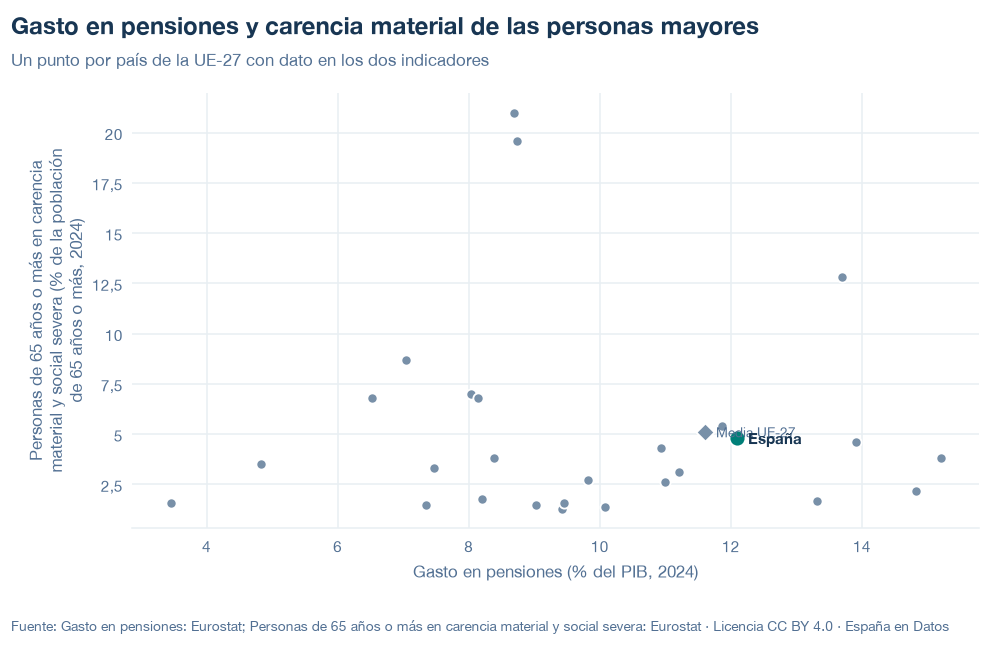

   codigo  anio     x    y
      AUT  2024 14.82  2.2
      BEL  2024 11.21  3.1
      BGR  2024  8.69 21.0
      CYP  2024  7.35  1.5
      CZE  2024  8.21  1.8
      DEU  2024 10.94  4.3
      DNK  2024  9.02  1.5
      ESP  2024 12.10  4.8
      EST  2024  7.47  3.3
      FIN  2024 13.31  1.7
      FRA  2024 13.91  4.6
      GRC  2024 13.69 12.8
      HRV  2024  8.39  3.8
      HUN  2024  7.04  8.7
      IRL  2024  3.45  1.6
      ITA  2024 15.20  3.8
      LTU  2024  6.52  6.8
      LUX  2024  9.42  1.3
      LVA  2024  8.04  7.0
      MLT  2024  4.83  3.5
      NLD  2024  9.46  1.6
      POL  2024 10.99  2.6
      PRT  2024 11.87  5.4
      ROU  2024  8.73 19.6
      SVK  2024  8.14  6.8
      SVN  2024  9.82  2.7
      SWE  2024 10.08  1.4
EU27_2020  2024 11.61  5.1


In [ ]:
datos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
)
fig = estilos.figura(datos, titulo=TITULO)
estilos.mostrar(fig)
print(pd.DataFrame(datos["puntos"]).to_string(index=False))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web (`codigo;pais;anio;eje_x;eje_y`).

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/gasto-pensiones-carencia-mayores.json y data/gasto-pensiones-carencia-mayores.csv


## 6. Fuentes, notas y licencia

- Eurostat, ESSPROS: `spr_exp_pens` (`OLD`, `AOLD`, `PART`, `SRV` y `TOTAL`, `spdepm=TOTAL`, `PC_GDP`).
- Eurostat, EU-SILC: `ilc_mdsd11` (`Y_GE65`, `sex=T`, `PC`).

La fecha de consulta de cada eje está en `fuentes` del JSON; las notas incluyen los países sin dato y la advertencia de que la relación no muestra causa.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.